# 01. Khảo sát dữ liệu (EDA) - Dự báo nhu cầu điện năng

**Mục tiêu:** dự báo lượng điện (kW trung bình) của **giờ kế tiếp** từ **24 giờ gần nhất** cho một khách hàng.
Notebook này trả lời: dữ liệu có sạch không, chọn chuỗi nào, chia tập ra sao, có điểm bất thường nào cần ghi nhớ.

**Cách chạy:** mở notebook trong thư mục `notebooks/`, chạy lần lượt từ trên xuống (cần đã có `data/processed/series_hourly.csv`,
tạo bởi `python src/data_preprocessing.py`).

**Quy ước dữ liệu:** giá trị là kW trung bình mỗi giờ; nhãn thời gian là *mốc kết thúc* của giờ (mốc 02:00 gồm 01:15 đến 02:00).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.config import load_config, path_from, set_seed
from src.data import load_hourly_data, split_by_time
from src.dst_check import dst_table

cfg = load_config()
set_seed(cfg["project"]["seed"])
FIG_DIR = path_from(cfg, "figures_dir"); FIG_DIR.mkdir(parents=True, exist_ok=True)
MAIN = cfg["customers"]["main"]
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
print("Chuỗi chính:", MAIN)

Chuỗi chính: MT_158


## 1. Tổng quan dữ liệu theo giờ

In [2]:
df = load_hourly_data(cfg)   # kiểm tra: không trùng, không thiếu, không âm, cách đều 1 giờ
train, val, test = split_by_time(df, cfg)
print("Số giờ:", len(df), "| từ", df.index.min(), "đến", df.index.max())
print("Giá trị thiếu:", int(df.isna().sum().sum()), "| giá trị bằng 0:", int((df == 0).sum().sum()))
df.describe().round(2)

Số giờ: 35064 | từ 2011-01-01 01:00:00 đến 2015-01-01 00:00:00
Giá trị thiếu: 0 | giá trị bằng 0: 0


,MT_156,MT_158,MT_159,MT_168,MT_169
count,35064.00,35064.00,35064.00,35064.00,35064.00
mean,78.01,75.51,61.92,137.12,40.03
std,28.12,52.05,46.02,44.73,11.24
min,1.40,5.55,1.20,14.60,7.06
25%,64.30,28.30,17.49,95.93,28.77
50%,75.85,65.43,43.37,152.20,43.52
75%,90.67,115.57,109.75,171.73,49.58
max,177.04,231.96,166.66,245.77,71.32


Dữ liệu có đúng 35.064 giờ (4 năm), không thiếu, không trùng, không giá trị 0 và không âm ở cả 5 chuỗi đã chọn.
Việc kiểm tra tự động nằm trong `load_hourly_data`: nếu sau này dữ liệu bị lỗi, hàm sẽ báo lỗi thay vì chạy tiếp.

## 2. So sánh các chuỗi ứng viên

In [3]:
def longest_constant_run(s):
    same = s.diff() == 0
    runs = same.groupby((~same).cumsum()).sum()
    return int(runs.max()), int((runs >= 6).sum())

rows = []
for c in df.columns:
    s = df[c]
    run_max, run6 = longest_constant_run(s)
    rows.append({"customer": c, "mean_kW": s.mean(), "std_kW": s.std(), "cv(std/mean)": s.std() / s.mean(),
                 "max_kW": s.max(), "giờ_không_đổi_dài_nhất": run_max, "số_đoạn_không_đổi_>=6h": run6,
                 "autocorr_lag1": s.autocorr(1), "autocorr_lag24": s.autocorr(24), "autocorr_lag168": s.autocorr(168)})
compare = pd.DataFrame(rows).set_index("customer").round(2)
compare.to_csv(path_from(cfg, "tables_dir") / "customer_comparison_hourly.csv", encoding="utf-8-sig")
compare

,mean_kW,std_kW,cv(std/mean),max_kW,giờ_không_đổi_dài_nhất,số_đoạn_không_đổi_>=6h,autocorr_lag1,autocorr_lag24,autocorr_lag168
customer,,,,,,,,,
MT_156,78.01,28.12,0.36,177.04,215,230,0.95,0.67,0.84
MT_158,75.51,52.05,0.69,231.96,4,0,0.88,0.56,0.89
MT_159,61.92,46.02,0.74,166.66,5,0,0.93,0.57,0.88
MT_168,137.12,44.73,0.33,245.77,1,0,0.88,0.96,0.95
MT_169,40.03,11.24,0.28,71.32,2,0,0.92,0.95,0.94


**Nhận xét**

- **MT_156** có đoạn không đổi dài tới 215 giờ liên tiếp và 230 đoạn không đổi từ 6 giờ trở lên: chuỗi có nhiều đoạn phẳng, ít thông tin để học, nên loại.
- **MT_158 và MT_159** không có đoạn phẳng, độ biến thiên (cv) lớn (khoảng 0,7), tự tương quan lag 168 cao (khoảng 0,88-0,89) và lag 24 thấp hơn (khoảng 0,56-0,57): chu kỳ tuần rõ, ngày thường khác cuối tuần.
- **MT_168 và MT_169** rất đều đặn: tự tương quan lag 24 và lag 168 đều khoảng 0,94-0,96. Vì vậy các baseline Seasonal Naive sẽ là đối thủ rất mạnh với hai chuỗi này.
- Chuỗi chính đề xuất: **MT_158**; chuỗi phụ (tùy chọn): **MT_168, MT_169**. Đây là đề xuất dựa trên chất lượng dữ liệu, chọn *trước khi* chạy mô hình, không dựa trên kết quả dự báo.

## 3. Chuỗi chính MT_158

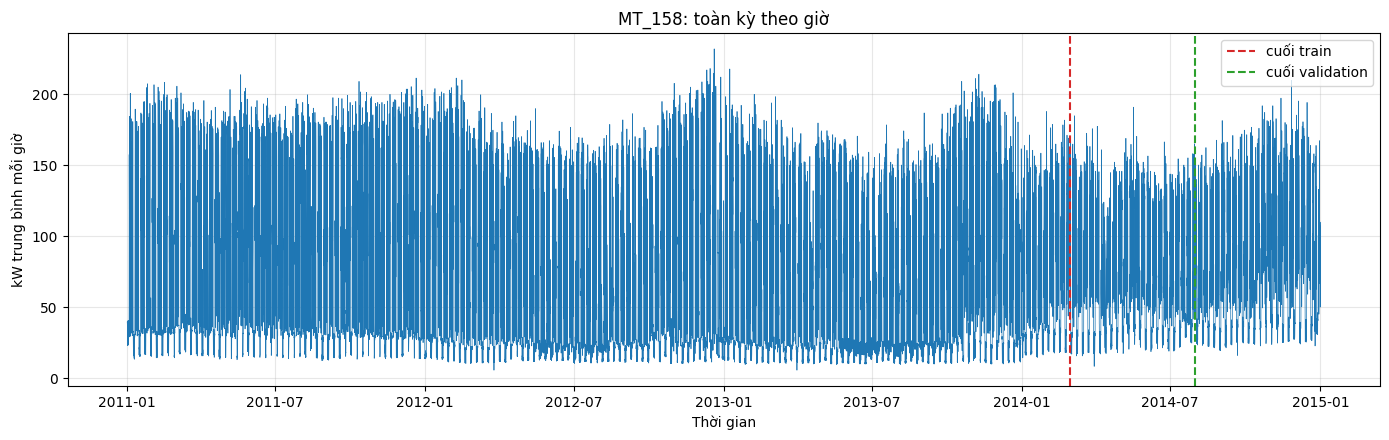

In [4]:
s = df[MAIN]
train_end, val_end = pd.Timestamp(cfg["split"]["train_end"]), pd.Timestamp(cfg["split"]["val_end"])
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(s.index, s.values, lw=0.5)
ax.axvline(train_end, color="tab:red", ls="--", label="cuối train")
ax.axvline(val_end, color="tab:green", ls="--", label="cuối validation")
ax.set(title=f"{MAIN}: toàn kỳ theo giờ", xlabel="Thời gian", ylabel="kW trung bình mỗi giờ"); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_main_full_series.png", dpi=150); plt.show()

Chuỗi dao động đều quanh một biên độ lớn với chu kỳ rõ, không có khoảng trống hay đoạn phẳng dài. Mức nền ban đêm thay đổi nhẹ theo năm (xem mục 4).

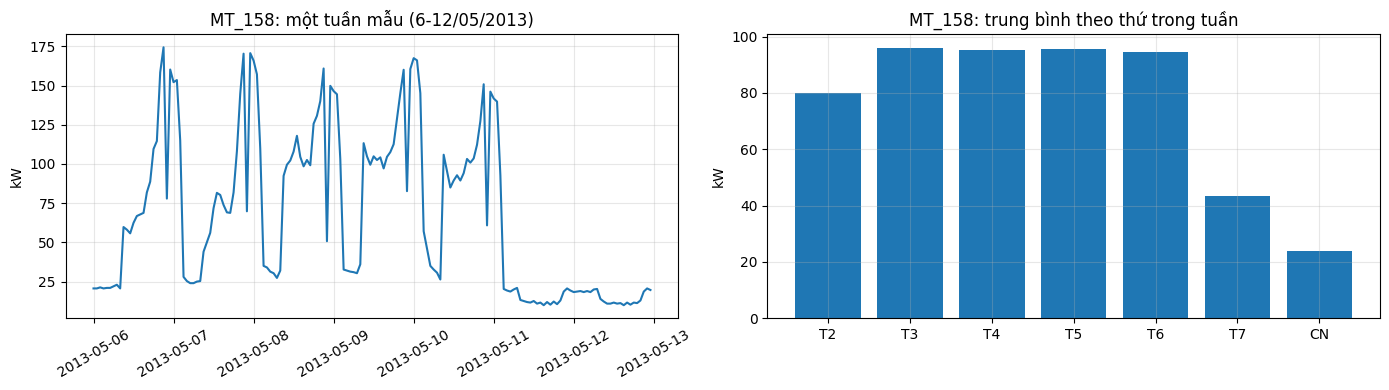

timestamp
T2    80.0
T3    96.0
T4    95.1
T5    95.6
T6    94.7
T7    43.5
CN    23.9
Name: MT_158, dtype: float64

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
week = s.loc["2013-05-06":"2013-05-12"]
axes[0].plot(week.index, week.values); axes[0].set(title=f"{MAIN}: một tuần mẫu (6-12/05/2013)", ylabel="kW")
axes[0].tick_params(axis="x", rotation=30)
wd = s.groupby(s.index.dayofweek).mean()
axes[1].bar(["T2", "T3", "T4", "T5", "T6", "T7", "CN"], wd.values)
axes[1].set(title=f"{MAIN}: trung bình theo thứ trong tuần", ylabel="kW")
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_main_week_and_weekday.png", dpi=150); plt.show()
wd.round(1).rename(index=dict(enumerate(["T2", "T3", "T4", "T5", "T6", "T7", "CN"])))

Ngày thường (thứ Ba đến thứ Sáu) có mức tiêu thụ trung bình cao (khoảng 95 kW), thứ Bảy thấp hơn nhiều (khoảng 44 kW) và Chủ nhật thấp nhất (khoảng 24 kW). Đây là lý do **Seasonal Naive lag 168** (cùng giờ tuần trước) hợp lý hơn lag 24 cho chuỗi này, và cũng là lý do cần thử cửa sổ 168 giờ ở bước cải tiến.

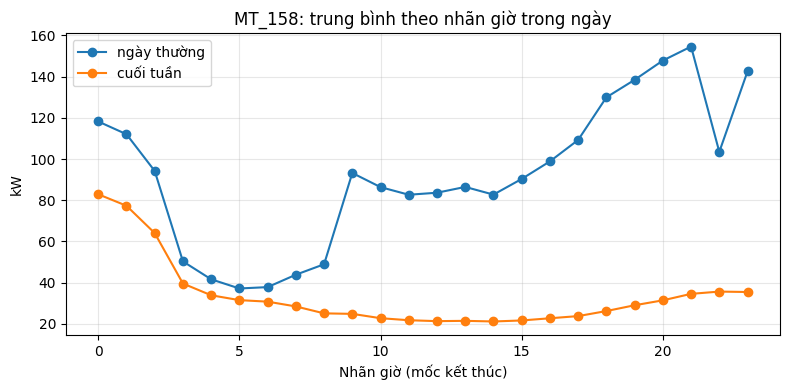

In [6]:
h = s.index.hour
is_weekend = s.index.dayofweek >= 5
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(24), s[~is_weekend].groupby(h[~is_weekend]).mean(), marker="o", label="ngày thường")
ax.plot(range(24), s[is_weekend].groupby(h[is_weekend]).mean(), marker="o", label="cuối tuần")
ax.set(title=f"{MAIN}: trung bình theo nhãn giờ trong ngày", xlabel="Nhãn giờ (mốc kết thúc)", ylabel="kW"); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_main_hour_profile.png", dpi=150); plt.show()

Ngày thường: mức cao vào buổi tối và đầu giờ sáng (nhãn khoảng 19-02), thấp nhất khoảng nhãn 03-08, tăng nhảy bậc ở nhãn 09 rồi giữ mức trung bình ban ngày. Có một điểm tụt riêng ở nhãn 22 rồi bật lại ở nhãn 23, chưa rõ nguyên nhân (có thể do lịch vận hành hoặc biểu giá điện của khách hàng; chỉ là giả thuyết, cần kiểm chứng thêm trước khi kết luận). Cuối tuần thấp và phẳng hơn nhiều. Đây là cấu trúc mà mô hình cần học và baseline theo mùa vụ cần so sánh.

## 4. Mức tải theo năm và khác biệt giữa train / validation / test

,MT_156,MT_158,MT_159,MT_168,MT_169
năm,,,,,
2011,80.0,89.8,96.4,144.1,40.8
2012,61.7,67.4,57.0,137.1,38.8
2013,84.1,68.2,49.0,133.7,39.4
2014,86.3,76.7,45.3,133.6,41.1


,MT_156,MT_158,MT_159,MT_168,MT_169
train,75.4,75.2,67.4,138.1,39.7
validation,88.5,71.4,34.8,130.9,40.8
test,87.4,82.1,47.5,136.0,42.1


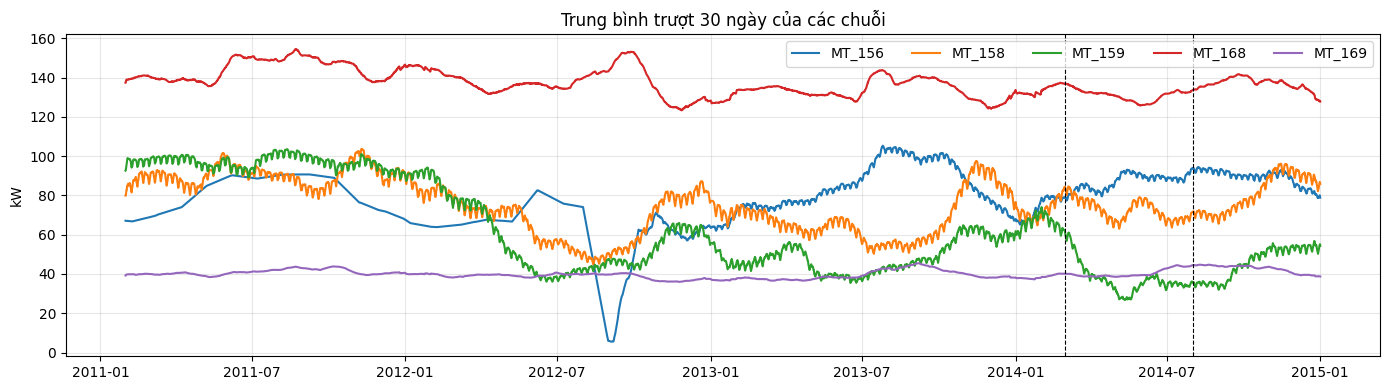

In [7]:
year = (df.index - pd.Timedelta(hours=1)).year   # nhãn là mốc kết thúc, giờ 00:00 ngày 01/01/2015 thuộc 2014
by_year = df.groupby(year).mean().round(1)
by_year.index.name = "năm"
display(by_year)
by_split = pd.DataFrame({"train": train.mean(), "validation": val.mean(), "test": test.mean()}).T.round(1)
display(by_split)
fig, ax = plt.subplots(figsize=(14, 4))
for c in df.columns:
    ax.plot(df[c].rolling(24 * 30).mean(), label=c)
ax.axvline(train_end, color="k", ls="--", lw=0.8); ax.axvline(val_end, color="k", ls="--", lw=0.8)
ax.set(title="Trung bình trượt 30 ngày của các chuỗi", ylabel="kW"); ax.legend(ncol=5)
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_rolling_mean_all.png", dpi=150); plt.show()

**Nhận xét**

- **MT_158**: trung bình theo năm là 89,8 (2011), khoảng 67-68 (2012-2013) và 76,7 (2014). Mức nền ban đêm cũng nhích lên trong 2014. Tập validation và test thuộc phần có mức nền khác so với phần lớn tập train.
- **MT_159**: giảm gần như đều theo năm (96 -> 45), trung bình tập train 67, validation 35, test 47. Lệch phân phối khá mạnh, nên chỉ dùng làm chuỗi dự phòng.
- **MT_168, MT_169**: gần như ổn định qua các năm, phù hợp làm chuỗi phụ để kiểm tra tính tổng quát.
- Cần ghi vào phần *hạn chế* của báo cáo: dữ liệu có dịch mức theo năm; validation (tháng 3-7/2014) và test (tháng 8-12/2014) thuộc các mùa khác nhau và khác mức tải với phần lớn tập train.

## 5. Chia train / validation / test (80/10/10 theo thời gian)

In [8]:
from src.data import split_summary
split_tbl = split_summary({"train": train, "validation": val, "test": test})
display(split_tbl.iloc[:, :5])
print("Tổng:", len(train) + len(val) + len(test), "giờ")

,split,rows,percent,start,end
0,train,27720,79.06,2011-01-01 01:00:00,2014-03-01
1,validation,3672,10.47,2014-03-01 01:00:00,2014-08-01
2,test,3672,10.47,2014-08-01 01:00:00,2015-01-01


Tổng: 35064 giờ


Mốc cắt theo ranh giới tháng (cắt theo thời gian, không xáo trộn): train 27.720 giờ (79,1%), validation 3.672 giờ (10,5%), test 3.672 giờ (10,5%); validation và test mỗi tập 153 ngày. Khi tạo cửa sổ, 24 giờ đầu vào của các mẫu đầu validation/test được lấy từ cuối tập trước (dữ liệu quá khứ, hợp lệ), còn nhãn dự báo phải nằm đúng trong tập của nó. Bộ chuẩn hóa nếu dùng chỉ được fit trên tập train.

## 6. Giờ bất thường quanh ngày chuyển giờ (DST)

In [9]:
dst = dst_table(df, cfg)
dst.to_csv(path_from(cfg, "tables_dir") / "dst_hours.csv", index=False)
display(dst[dst.customer == MAIN].drop(columns="customer"))
print("Số ngày được gợi ý kiểm tra theo chuỗi:")
print(dst.groupby("customer")["suggest_check"].sum().to_string())

,date,kind,hour_label,split,value_01h,value_02h,value_03h,ratio_vs_neighbors,suggest_check
1,2011-03-27,march,2011-03-27 02:00:00,train,53.05,33.65,36.66,0.75,False
6,2011-10-30,october,2011-10-30 02:00:00,train,34.99,30.64,32.98,0.90,False
11,2012-03-25,march,2012-03-25 02:00:00,train,15.25,5.55,22.28,0.30,True
16,2012-10-28,october,2012-10-28 02:00:00,train,30.31,42.01,23.95,1.55,True
21,2013-03-31,march,2013-03-31 02:00:00,train,14.25,5.55,18.26,0.34,True
26,2013-10-27,october,2013-10-27 02:00:00,train,29.31,38.67,22.61,1.49,True
31,2014-03-30,march,2014-03-30 02:00:00,validation,22.95,8.23,30.64,0.31,True
36,2014-10-26,october,2014-10-26 02:00:00,test,45.69,62.76,35.99,1.54,True


Số ngày được gợi ý kiểm tra theo chuỗi:
customer
MT_156    7
MT_158    6
MT_159    7
MT_168    6
MT_169    6


**Nhận xét**

- Ở các ngày chuyển giờ tháng 3 (2012, 2013, 2014), giờ nhãn 02:00 tụt xuống chỉ còn khoảng 0,13-0,35 lần so với các giờ lân cận ở cả 5 chuỗi; ở tháng 10 (2012-2014) giờ này tăng khoảng 1,4-1,6 lần ở đa số chuỗi (giờ bị gộp). Năm 2011 không thấy hiện tượng rõ ở chuỗi MT_158.
- Với MT_158 và MT_159, tỷ lệ này cũng có thể xuất hiện ở ngày thường do biến động mạnh, nên cột `suggest_check` chỉ là gợi ý; bằng chứng rõ nhất nằm ở chuỗi MT_168, MT_169 (đúng 6 ngày được gợi ý, trùng các ngày chuyển giờ 2012-2014).
- Mốc tháng 3/2014 nằm trong tập **validation** và mốc tháng 10/2014 nằm trong tập **test**: chúng có thể tạo lỗi dự báo lớn. Quyết định: **giữ nguyên dữ liệu**, ghi lại các mốc này (file `results/tables/dst_hours.csv`) và dùng để giải thích lỗi khi phân tích lỗi.

## 7. Kết luận và việc tiếp theo

**Quyết định về dữ liệu (đề xuất, nhóm xác nhận):**

1. Chuỗi chính **MT_158**; chuỗi phụ tùy chọn **MT_168, MT_169**; loại **MT_156**; **MT_159** giữ dự phòng.
2. Dữ liệu theo giờ (kW trung bình), 35.064 giờ, không thiếu và không giá trị 0.
3. Chia theo thời gian: train đến 2014-03-01 00:00, validation đến 2014-08-01 00:00, phần còn lại là test (27.720 / 3.672 / 3.672 giờ).
4. Baseline cần có: Last Value, Moving Average, Seasonal Naive lag 24 và lag 168.

**Hạn chế cần nêu trong báo cáo:** dịch mức theo năm; validation/test khác mùa và khác mức nền so với train; các giờ bất thường quanh ngày chuyển giờ.

**Việc tiếp theo:** baseline và hàm đánh giá (`src/baseline.py`, `src/metrics.py`), tạo cửa sổ trượt, MLP và LSTM.